# Exploración del conjunto de datos

**Proyecto final MIA-203: enfermedades en hojas de papa, CNN frente a ViT.**

Dataset: Shabrina et al., *Potato Leaf Disease Dataset in Uncontrolled Environment*, Mendeley Data, DOI [10.17632/ptz377bwb8.1](https://doi.org/10.17632/ptz377bwb8.1) (CC BY 4.0).

Este notebook revisa el tamaño del dataset, el desbalance de clases, los duplicados que encontramos en la auditoría, que la partición no tenga fuga y cómo son las fotos. Esas observaciones justifican varias decisiones de la metodología:
- la entropía cruzada ponderada;
- el macro-F1 como métrica;
- la partición por grupos;
- el aumento de datos.

**Qué necesita:**
- **Secciones 1 a 3:** solo los archivos de `data/splits/`, que están en el repositorio.
- **Secciones 4 y 5:** las imágenes. Se obtienen con `python src/download_data.py`, unos 750 MB. Si no están, esas celdas se saltan.

In [1]:
import json, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("papa-cnn-vs-vit").exists():
    !git clone -q https://github.com/gabo2607/papa-cnn-vs-vit.git
    %cd papa-cnn-vs-vit

RAIZ = Path.cwd() if (Path.cwd() / "data/splits").exists() else Path.cwd().parent
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(RAIZ / "data/splits/papa_split.csv")
elim = pd.read_csv(RAIZ / "data/splits/papa_eliminadas.csv")
resumen = json.loads((RAIZ / "data/splits/papa_split_resumen.json").read_text(encoding="utf-8"))
CLASES = ["bacteria", "fungi", "healthy", "nematode", "pest", "phytophthora", "virus"]
HAY_IMAGENES = (RAIZ / df.path.iloc[0]).exists()
print(f"Imágenes disponibles localmente: {HAY_IMAGENES}")

Imágenes disponibles localmente: True


## 1. Tamaño del conjunto

In [2]:
print(f"Fotos originales: {resumen['total_original']}")
print(f"Eliminadas en la auditoría: {len(elim)}  ->  quedan {len(df)}")
print("\nResolución de las fotos originales (ancho x alto):")
print(pd.concat([df, elim])[["w", "h"]].value_counts().rename("n").to_string())

Fotos originales: 3076
Eliminadas en la auditoría: 61  ->  quedan 3015

Resolución de las fotos originales (ancho x alto):
w     h   
1500  1500    3076


## 2. Distribución de clases y desbalance

split,train,val,test,total,% del total
label,,,,,
bacteria,397,86,86,569,18.9
fungi,518,110,112,740,24.5
healthy,139,30,30,199,6.6
nematode,47,10,10,67,2.2
pest,421,90,90,601,19.9
phytophthora,217,46,46,309,10.2
virus,373,78,79,530,17.6


Razón de desbalance (clase mayor / menor): 11.0x


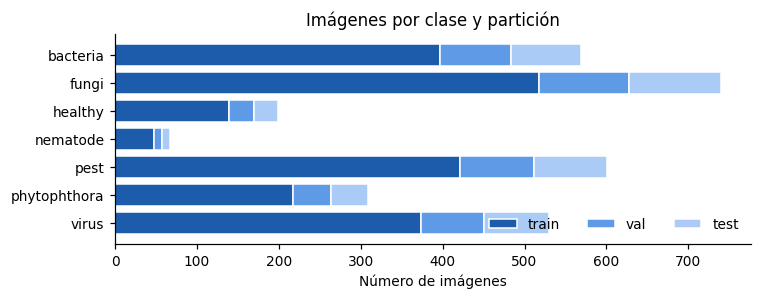

In [3]:
tabla = pd.crosstab(df.label, df.split).reindex(CLASES)[["train", "val", "test"]]
tabla["total"] = tabla.sum(1)
tabla["% del total"] = (100 * tabla.total / tabla.total.sum()).round(1)
display(tabla)
print(f"Razón de desbalance (clase mayor / menor): {tabla.total.max() / tabla.total.min():.1f}x")

fig, ax = plt.subplots(figsize=(7, 2.8))
izq = np.zeros(len(CLASES))
for parte, color in [("train", "#1c5cab"), ("val", "#5f9ae6"), ("test", "#a9cbf5")]:
    ax.barh(CLASES[::-1], tabla[parte][::-1], left=izq, color=color, label=parte, edgecolor="white")
    izq += tabla[parte][::-1].to_numpy()
ax.set_xlabel("Número de imágenes")
ax.legend(frameon=False, ncol=3, loc="lower right")
ax.set_title("Imágenes por clase y partición")
plt.tight_layout(); plt.show()

**Lectura:** hay casi 11 veces más fotos de *hongos* que de *nematodos*, y el test de nematodos tiene solo 10 imágenes. Con este desbalance, la accuracy premia predecir siempre las clases grandes. Por eso usamos **macro-F1** y **pesos por clase** en la pérdida.

## 3. Auditoría de duplicados y fuga de datos

In [4]:
print(f"Imágenes que forman pares de duplicados exactos (mismo sha256): {resumen['duplicados_exactos']}")
print("\nEliminadas por motivo:")
print(elim.motivo.value_counts().to_string())

# pares contradictorios: la misma foto (mismo sha256) en dos clases distintas
todas = pd.concat([df.assign(estado="conservada"), elim.assign(estado="eliminada")])
contra = elim[elim.motivo.str.contains("contradictoria")]
pares = (todas[todas.sha256.isin(contra.sha256)].groupby("sha256").label
         .apply(lambda s: " / ".join(sorted(s))).value_counts())
print("\nClases en conflicto (misma foto etiquetada con dos clases):")
print(pares.to_string())

Imágenes que forman pares de duplicados exactos (mismo sha256): 110

Eliminadas por motivo:
motivo
copia exacta repetida                                 49
misma imagen en 2 clases (etiqueta contradictoria)    12

Clases en conflicto (misma foto etiquetada con dos clases):
label
fungi / pest       3
pest / virus       1
healthy / pest     1
nematode / pest    1


In [5]:
tam = df.groupby("group").size()
print(f"Grupos de casi-duplicados (dHash, Hamming <= {resumen['hamming']}): {(tam > 1).sum()} grupos con {tam[tam > 1].sum()} imágenes")

# verificación de fuga: ningún grupo, sha256 ni dHash aparece en dos particiones
for col in ["group", "sha256", "dhash"]:
    en_varias = (df.groupby(col).split.nunique() > 1).sum()
    print(f"{col:7s} presente en más de una partición: {en_varias}")

Grupos de casi-duplicados (dHash, Hamming <= 4): 32 grupos con 64 imágenes
group   presente en más de una partición: 0
sha256  presente en más de una partición: 0
dhash   presente en más de una partición: 0


**Lectura:** el dataset público trae fotos repetidas, y algunas incluso con dos etiquetas distintas. Si una copia queda en entrenamiento y otra en prueba, el resultado se infla. Eliminamos las contradictorias y las repetidas, y partimos **por grupos** de fotos casi idénticas. Las tres comprobaciones dan 0: no hay fuga entre entrenamiento, validación y prueba.

## 4. Ejemplos por clase

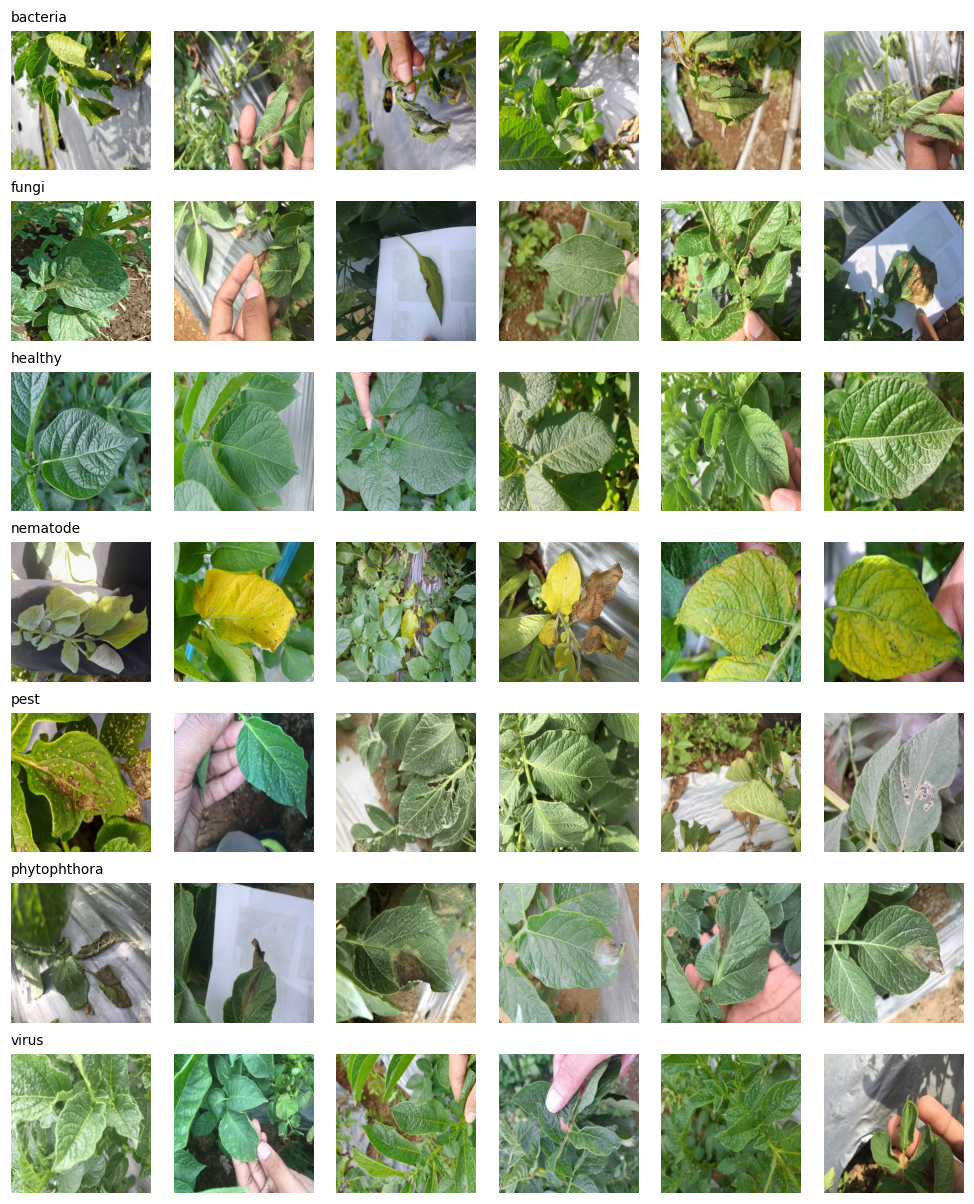

In [6]:
if HAY_IMAGENES:
    rng = np.random.default_rng(0)
    fig, axs = plt.subplots(len(CLASES), 6, figsize=(9, 11))
    for i, cl in enumerate(CLASES):
        rutas = df[(df.label == cl) & (df.split == "train")].path.to_numpy()
        for j, r in enumerate(rng.choice(rutas, 6, replace=False)):
            axs[i, j].imshow(Image.open(RAIZ / r)); axs[i, j].axis("off")
        axs[i, 0].set_title(cl, loc="left", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("Sin imágenes: ejecute `python src/download_data.py` para ver esta sección.")

## 5. Brillo y color por clase

,brillo,R,G,B
clase,,,,
bacteria,0.480,0.513,0.539,0.387
fungi,0.442,0.447,0.513,0.366
healthy,0.465,0.451,0.543,0.402
nematode,0.443,0.511,0.532,0.287
pest,0.485,0.494,0.547,0.412
phytophthora,0.499,0.497,0.560,0.440
virus,0.471,0.471,0.563,0.377


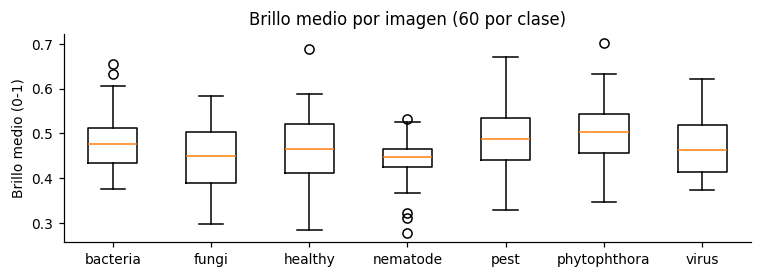

In [7]:
if HAY_IMAGENES:
    filas = []
    for cl in CLASES:
        for r in df[df.label == cl].path.sample(60, random_state=0):
            a = np.asarray(Image.open(RAIZ / r).convert("RGB"), dtype=np.float32) / 255
            filas.append({"clase": cl, "brillo": a.mean(), "R": a[..., 0].mean(), "G": a[..., 1].mean(), "B": a[..., 2].mean()})
    color = pd.DataFrame(filas)
    display(color.groupby("clase")[["brillo", "R", "G", "B"]].mean().reindex(CLASES).round(3))
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.boxplot([color[color.clase == cl].brillo for cl in CLASES], tick_labels=CLASES)
    ax.set_ylabel("Brillo medio (0-1)"); ax.set_title("Brillo medio por imagen (60 por clase)")
    plt.tight_layout(); plt.show()
else:
    print("Sin imágenes: ejecute `python src/download_data.py` para ver esta sección.")

## 6. Conclusiones de la exploración

| Observación | Decisión en la metodología |
|---|---|
| Desbalance de 11x (hongos 740 frente a nematodos 67) | Entropía cruzada **ponderada por clase** y **macro-F1** como métrica principal |
| 110 imágenes en 55 pares de duplicados exactos; 6 pares con dos etiquetas distintas | Eliminamos 12 imágenes contradictorias y 49 copias: quedan 3,015 |
| 64 imágenes en 32 grupos de casi-duplicados | Partición 70/15/15 **por grupos**; las comprobaciones de fuga dan 0 |
| Fotos de campo con plástico de cobertura, manos y varias hojas | **Aumento de datos** (recorte, volteo, rotación, color) y Grad-CAM para detectar atajos del fondo |
| El brillo medio es parecido entre clases (0.44 a 0.50) | El brillo por sí solo no separa las clases; nematodos tiene menos azul (hojas amarillentas) |
| **5 de los 6 pares contradictorios involucran a *plaga*** (3 de ellos *hongos/plaga*) | El propio dataset confunde *plaga* y *hongos*, y es el error más frecuente de los modelos (Sección IV-D del artículo) |

Todas las cifras de esta tabla se regeneran ejecutando el notebook.